# 1. Problema de negocio y base de datos

El objetivo es predecir si un conductor presentará un reclamo/siniestro. `target=1` representa el reclamo y será la clase positiva. La predicción puede apoyar la evaluación de riesgo; los costos de error se definirán después como supuestos académicos.

Fuente: [Porto Seguro en OpenML, data_id=42742](https://www.openml.org/d/42742). Se verifica la clase minoritaria y los requisitos con los datos cargados, sin asumir los resultados de ejecuciones anteriores.

In [1]:
# Importar bibliotecas y localizar el proyecto.
from pathlib import Path
import sys
import json
import gzip
import cloudpickle
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

SEMILLA = 2026
RAIZ = Path.cwd()
if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent
assert (RAIZ / "scripts").is_dir(), "Ejecuta desde la raíz del proyecto o notebooks/."
RESULTADOS = RAIZ / "resultados"
RESULTADOS.mkdir(exist_ok=True)
sys.path.insert(0, str(RAIZ / "scripts"))

In [2]:
# Descargar automáticamente solo si no existe la copia local.
from descargar_porto_seguro import descargar_datos
ruta_csv = RAIZ / "data" / "raw" / "porto_seguro.csv"
if not ruta_csv.exists():
    descargar_datos()
df = pd.read_csv(ruta_csv)
objetivo = "target"
print("Shape:", df.shape)
print("Columnas:", df.columns.tolist())
print("Objetivo:", objetivo)
display(df.head())
conteo_clases = df[objetivo].value_counts().sort_index()
distribucion_clases = pd.DataFrame({
    "Cantidad": conteo_clases,
    "Porcentaje": conteo_clases / len(df) * 100
})
display(distribucion_clases)

Shape: (595212, 58)
Columnas: ['ps_ind_01', 'ps_ind_02_cat', 'ps_ind_03', 'ps_ind_04_cat', 'ps_ind_05_cat', 'ps_ind_06_bin', 'ps_ind_07_bin', 'ps_ind_08_bin', 'ps_ind_09_bin', 'ps_ind_10_bin', 'ps_ind_11_bin', 'ps_ind_12_bin', 'ps_ind_13_bin', 'ps_ind_14', 'ps_ind_15', 'ps_ind_16_bin', 'ps_ind_17_bin', 'ps_ind_18_bin', 'ps_reg_01', 'ps_reg_02', 'ps_reg_03', 'ps_car_01_cat', 'ps_car_02_cat', 'ps_car_03_cat', 'ps_car_04_cat', 'ps_car_05_cat', 'ps_car_06_cat', 'ps_car_07_cat', 'ps_car_08_cat', 'ps_car_09_cat', 'ps_car_10_cat', 'ps_car_11_cat', 'ps_car_11', 'ps_car_12', 'ps_car_13', 'ps_car_14', 'ps_car_15', 'ps_calc_01', 'ps_calc_02', 'ps_calc_03', 'ps_calc_04', 'ps_calc_05', 'ps_calc_06', 'ps_calc_07', 'ps_calc_08', 'ps_calc_09', 'ps_calc_10', 'ps_calc_11', 'ps_calc_12', 'ps_calc_13', 'ps_calc_14', 'ps_calc_15_bin', 'ps_calc_16_bin', 'ps_calc_17_bin', 'ps_calc_18_bin', 'ps_calc_19_bin', 'ps_calc_20_bin', 'target']
Objetivo: target


,ps_ind_01,ps_ind_02_cat,ps_ind_03,ps_ind_04_cat,ps_ind_05_cat,ps_ind_06_bin,ps_ind_07_bin,ps_ind_08_bin,ps_ind_09_bin,ps_ind_10_bin,...,ps_calc_12,ps_calc_13,ps_calc_14,ps_calc_15_bin,ps_calc_16_bin,ps_calc_17_bin,ps_calc_18_bin,ps_calc_19_bin,ps_calc_20_bin,target
0,2.0,2.0,5.0,1.0,0.0,0,1,0,0,0,...,1.0,5.0,8.0,0,1,1,0,0,1,0
1,1.0,1.0,7.0,0.0,0.0,0,0,1,0,0,...,1.0,1.0,9.0,0,1,1,0,1,0,0
2,5.0,4.0,9.0,1.0,0.0,0,0,1,0,0,...,2.0,7.0,7.0,0,1,1,0,1,0,0
3,0.0,1.0,2.0,0.0,0.0,1,0,0,0,0,...,2.0,4.0,9.0,0,0,0,0,0,0,0
4,0.0,2.0,0.0,1.0,0.0,1,0,0,0,0,...,1.0,1.0,3.0,0,0,0,1,1,0,0


,Cantidad,Porcentaje
target,,
0,573518,96.355248
1,21694,3.644752


In [3]:
# Verificar formalmente los requisitos con valores observados.
identificadores = [c for c in df.columns if c.lower() == "id"]
predictoras = [c for c in df.columns if c not in [objetivo] + identificadores]
clase_minoritaria = conteo_clases.idxmin()
porcentaje_minoritario = float(distribucion_clases.loc[clase_minoritaria, "Porcentaje"])
requisitos = {
    "Más de 100.000 registros": len(df) > 100_000,
    "Objetivo binario 0/1": set(df[objetivo].dropna().unique()) == {0, 1},
    "Clase minoritaria entre 1% y 30%": 1 <= porcentaje_minoritario <= 30,
    "Al menos 8 predictores": len(predictoras) >= 8,
    "Objetivo sin nulos": not df[objetivo].isna().any()
}
display(pd.DataFrame(requisitos.items(), columns=["Requisito", "Cumple"]))
print("Predictores:", len(predictoras))
print("Clase minoritaria:", clase_minoritaria, "| Porcentaje:", porcentaje_minoritario)
assert all(requisitos.values()) and clase_minoritaria == 1
with open(RAIZ / "data" / "validacion_porto_seguro.json", "w") as archivo:
    json.dump({"shape": list(df.shape), "predictores": len(predictoras),
               "clase_minoritaria": int(clase_minoritaria),
               "porcentaje_minoritario": porcentaje_minoritario,
               "requisitos": requisitos}, archivo, ensure_ascii=False, indent=2)

,Requisito,Cumple
0,Más de 100.000 registros,True
1,Objetivo binario 0/1,True
2,Clase minoritaria entre 1% y 30%,True
3,Al menos 8 predictores,True
4,Objetivo sin nulos,True


Predictores: 57
Clase minoritaria: 1 | Porcentaje: 3.6447517859182947


# 2. Exploración inicial

Se inspeccionan los datos originales sin imputar, eliminar filas ni ajustar transformaciones. `_cat` indica categorías nominales y `_bin` indicadores binarios. La descripción de OpenML identifica como ordinales las variables enteras restantes sin esos sufijos. No se interpreta la distancia entre categorías como una medida continua.

In [4]:
# Clasificar las columnas a partir del esquema documentado.
categoricas = [c for c in predictoras if c.endswith("_cat")]
binarias = [c for c in predictoras if c.endswith("_bin")]
ordinales = [
    "ps_ind_01", "ps_ind_03", "ps_ind_14", "ps_ind_15", "ps_car_11",
    "ps_calc_04", "ps_calc_05", "ps_calc_06", "ps_calc_07", "ps_calc_08",
    "ps_calc_09", "ps_calc_10", "ps_calc_11", "ps_calc_12", "ps_calc_13", "ps_calc_14"
]
numericas = [c for c in predictoras if c not in categoricas + binarias + ordinales]
grupos = {"Numérica": numericas, "Binaria": binarias,
          "Categórica": categoricas, "Ordinal": ordinales}
clasificacion_variables = pd.DataFrame([
    {"Variable": c, "Tipo": tipo, "dtype": str(df[c].dtype)}
    for tipo, columnas in grupos.items() for c in columnas
])
display(clasificacion_variables)
print("Identificadores excluidos:", identificadores)
print("Cantidad por tipo:", {tipo: len(cols) for tipo, cols in grupos.items()})
assert set(numericas + binarias + categoricas + ordinales) == set(predictoras)

,Variable,Tipo,dtype
0,ps_reg_01,Numérica,float64
1,ps_reg_02,Numérica,float64
2,ps_reg_03,Numérica,float64
3,ps_car_12,Numérica,float64
4,ps_car_13,Numérica,float64
5,ps_car_14,Numérica,float64
6,ps_car_15,Numérica,float64
7,ps_calc_01,Numérica,float64
8,ps_calc_02,Numérica,float64
9,ps_calc_03,Numérica,float64


Identificadores excluidos: []
Cantidad por tipo: {'Numérica': 10, 'Binaria': 17, 'Categórica': 14, 'Ordinal': 16}


In [5]:
# Revisar nulos, el código especial -1 y duplicados, sin reemplazar valores.
faltantes = pd.DataFrame({
    "Nulos": df[predictoras].isna().sum(),
    "Porcentaje_nulos": df[predictoras].isna().mean() * 100,
    "Codigo_menos_1": df[predictoras].eq(-1).sum()
})
display(faltantes)
print("Registros duplicados:", df.duplicated().sum())
display(df[numericas + ordinales].describe().T)
display(df[categoricas].nunique().to_frame("Cardinalidad_sin_nulos"))

,Nulos,Porcentaje_nulos,Codigo_menos_1
ps_ind_01,0,0.000000,0
ps_ind_02_cat,216,0.036290,0
ps_ind_03,0,0.000000,0
ps_ind_04_cat,83,0.013945,0
ps_ind_05_cat,5809,0.975955,0
ps_ind_06_bin,0,0.000000,0
ps_ind_07_bin,0,0.000000,0
ps_ind_08_bin,0,0.000000,0
ps_ind_09_bin,0,0.000000,0
ps_ind_10_bin,0,0.000000,0


Registros duplicados: 0


,count,mean,std,min,25%,50%,75%,max
ps_reg_01,595212.0,0.610991,0.287643,0.000000,0.400000,0.700000,0.900000,0.900000
ps_reg_02,595212.0,0.439184,0.404264,0.000000,0.200000,0.300000,0.600000,1.800000
ps_reg_03,487440.0,0.894047,0.345413,0.061237,0.633443,0.801561,1.083974,4.037945
ps_car_12,595211.0,0.379947,0.058300,0.100000,0.316228,0.374166,0.400000,1.264911
ps_car_13,595212.0,0.813265,0.224588,0.250619,0.670867,0.765811,0.906190,3.720626
ps_car_14,552592.0,0.374691,0.045610,0.109545,0.350428,0.373497,0.398121,0.636396
ps_car_15,595212.0,3.065899,0.731366,0.000000,2.828427,3.316625,3.605551,3.741657
ps_calc_01,595212.0,0.449756,0.287198,0.000000,0.200000,0.500000,0.700000,0.900000
ps_calc_02,595212.0,0.449589,0.286893,0.000000,0.200000,0.400000,0.700000,0.900000
ps_calc_03,595212.0,0.449849,0.287153,0.000000,0.200000,0.500000,0.700000,0.900000


,Cardinalidad_sin_nulos
ps_ind_02_cat,4
ps_ind_04_cat,2
ps_ind_05_cat,7
ps_car_01_cat,12
ps_car_02_cat,2
ps_car_03_cat,2
ps_car_04_cat,10
ps_car_05_cat,2
ps_car_06_cat,18
ps_car_07_cat,2


In [6]:
# Contar posibles outliers solo en numéricas, sin eliminarlos.
filas_outliers = []
for columna in numericas:
    q1, q3 = df[columna].quantile([0.25, 0.75])
    iqr = q3 - q1
    limite_inferior, limite_superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    cantidad = ((df[columna] < limite_inferior) | (df[columna] > limite_superior)).sum()
    filas_outliers.append({"Variable": columna, "IQR": iqr,
                           "Posibles_outliers": int(cantidad)})
display(pd.DataFrame(filas_outliers))

,Variable,IQR,Posibles_outliers
0,ps_reg_01,0.500000,0
1,ps_reg_02,0.400000,36793
2,ps_reg_03,0.450531,10562
3,ps_car_12,0.083772,15355
4,ps_car_13,0.235324,26913
5,ps_car_14,0.047692,18770
6,ps_car_15,0.777124,27409
7,ps_calc_01,0.500000,0
8,ps_calc_02,0.500000,0
9,ps_calc_03,0.500000,0


`-1` representa faltantes en el concurso original; esta copia de OpenML puede traerlos como NaN. Se comprueban ambos. La conversión se hará dentro del pipeline; los ceros se conservan como valores válidos. La regla IQR es exploratoria y no justifica eliminar registros automáticamente. La revisión inicial no calcula estadísticas que se reutilicen para imputar ni selecciona variables según su relación con el objetivo.

# 3. Partición Train/Test

Se usa estratificación para conservar aproximadamente el desbalance en ambos conjuntos. Test queda reservado: no participa en tuning ni en la selección del ganador. No se ajusta ningún preprocesamiento antes de dividir.

In [7]:
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV

X = df[predictoras].copy()
y = df[objetivo].copy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEMILLA
)
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("Porcentaje positivo train:", y_train.eq(1).mean() * 100)
print("Porcentaje positivo test:", y_test.eq(1).mean() * 100)
assert X_train.index.intersection(X_test.index).empty

X_train: (476169, 57)
X_test: (119043, 57)
Porcentaje positivo train: 3.6447143766183854
Porcentaje positivo test: 3.6449014221751805


# 4. Preprocesamiento

Todo el ajuste vive dentro del pipeline: conversión de `-1` a NaN, mediana para numéricas y moda para ordinales, binarias y categóricas. Las ordinales ya tienen códigos numéricos ordenados. Las nominales usan OneHotEncoder con categorías desconocidas ignoradas. No se escalan variables porque los modelos obligatorios son árboles o ensembles de árboles.

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone

def convertir_faltantes(datos):
    return datos.replace(-1, np.nan)

pipeline_numerico = Pipeline([
    ("imputar", SimpleImputer(strategy="median", keep_empty_features=True))
])
pipeline_discreto = Pipeline([
    ("imputar", SimpleImputer(strategy="most_frequent", keep_empty_features=True))
])
pipeline_categorico = Pipeline([
    ("imputar", SimpleImputer(strategy="most_frequent", keep_empty_features=True)),
    ("codificar", OneHotEncoder(handle_unknown="ignore", sparse_output=True))
])
columnas_transformadas = ColumnTransformer([
    ("numericas", pipeline_numerico, numericas),
    ("ordinales_binarias", pipeline_discreto, ordinales + binarias),
    ("categoricas", pipeline_categorico, categoricas)
], remainder="drop", sparse_threshold=1.0)
preprocesador = Pipeline([
    ("faltantes", FunctionTransformer(convertir_faltantes, validate=False)),
    ("columnas", columnas_transformadas)
])
print(preprocesador)

Pipeline(steps=[('faltantes',
                 FunctionTransformer(func=<function convertir_faltantes at 0x307132520>)),
                ('columnas',
                 ColumnTransformer(sparse_threshold=1.0,
                                   transformers=[('numericas',
                                                  Pipeline(steps=[('imputar',
                                                                   SimpleImputer(keep_empty_features=True,
                                                                                 strategy='median'))]),
                                                  ['ps_reg_01', 'ps_reg_02',
                                                   'ps_reg_03', 'ps_car_12',
                                                   'ps_car_13', 'ps_car_14',
                                                   'ps_car_15',...
                                                                   SimpleImputer(keep_empty_features=True,
                                    

En CV se clona y ajusta la preparación solamente dentro del entrenamiento de cada fold, evitando leakage. La salida dispersa limita el uso de memoria. SMOTE estándar, exigido en la Etapa A, puede interpolar códigos one-hot y generar dummy fraccionarias; se conserva el método exigido sin añadir otras técnicas.

# 5. Funciones auxiliares

Se reutilizan funciones pequeñas para métricas, costo, pipelines y entrenamiento. F1, recall y precisión se refieren siempre a la clase positiva 1. El tiempo se expresa en segundos.

In [9]:
from sklearn.metrics import (f1_score, recall_score, precision_score, roc_auc_score,
                             confusion_matrix, make_scorer)
from imblearn.pipeline import Pipeline as PipelineImblearn
from imblearn.over_sampling import SMOTE
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

scoring_f1 = make_scorer(f1_score, pos_label=1, zero_division=0)

def calcular_costo(y_real, pred, C_FP=100, C_FN=1000, pos_label=1):
    y_real, pred = np.asarray(y_real), np.asarray(pred)
    fp = int(((y_real != pos_label) & (pred == pos_label)).sum())
    fn = int(((y_real == pos_label) & (pred != pos_label)).sum())
    return fp * C_FP + fn * C_FN

def evaluar_clasificacion(y_real, pred, probabilidades=None, C_FP=100, C_FN=1000):
    tn, fp, fn, tp = confusion_matrix(y_real, pred, labels=[0, 1]).ravel()
    return {
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
        "Precision": precision_score(y_real, pred, pos_label=1, zero_division=0),
        "Recall": recall_score(y_real, pred, pos_label=1, zero_division=0),
        "F1": f1_score(y_real, pred, pos_label=1, zero_division=0),
        "AUC_ROC": roc_auc_score(y_real, probabilidades) if probabilidades is not None else np.nan,
        "Costo_total": calcular_costo(y_real, pred, C_FP, C_FN)
    }

In [10]:
# Preparar un pipeline nuevo en cada ajuste, sin compartir estadísticas.
# Imblearn no admite un Pipeline de sklearn como paso intermedio: se despliega la preparación.
def crear_pipeline(estimador, estrategia):
    pasos = [(nombre, clone(paso)) for nombre, paso in preprocesador.steps]
    if estrategia == "SMOTE":
        pasos.append(("smote", SMOTE(random_state=SEMILLA)))
    pasos.append(("modelo", clone(estimador)))
    if estrategia == "SMOTE":
        return PipelineImblearn(pasos)
    return Pipeline(pasos)

In [11]:
# Buscar en la submuestra y ajustar después con TODO train.
def ajustar_modelo(nombre, estrategia, estimador, espacio):
    carpeta = RESULTADOS / estrategia.lower()
    carpeta.mkdir(exist_ok=True)
    busqueda = RandomizedSearchCV(
        crear_pipeline(estimador, estrategia), espacio, n_iter=10,
        scoring=scoring_f1, cv=cv, random_state=SEMILLA,
        n_jobs=-1, pre_dispatch="n_jobs", refit=False,
        return_train_score=True, error_score=np.nan
    )
    inicio = perf_counter()
    busqueda.fit(X_busqueda, y_busqueda)
    segundos = perf_counter() - inicio
    assert np.isfinite(busqueda.best_score_), "Ninguna configuración tuvo CV válida."
    i = busqueda.best_index_
    ganador = crear_pipeline(estimador, estrategia).set_params(**busqueda.best_params_)
    inicio_refit = perf_counter()
    ganador.fit(X_train, y_train)
    resultado = {
        "mejores_hiperparametros": busqueda.best_params_,
        "F1_CV": float(busqueda.best_score_),
        "F1_folds": [float(busqueda.cv_results_[f"split{k}_test_score"][i]) for k in range(3)],
        "F1_std": float(busqueda.cv_results_["std_test_score"][i]),
        "F1_train_folds": float(busqueda.cv_results_["mean_train_score"][i]),
        "Tiempo_busqueda": segundos,
        "Tiempo_refit": perf_counter() - inicio_refit,
        "Configuraciones_validas": int(np.isfinite(busqueda.cv_results_["mean_test_score"]).sum()),
        "Registros_refit": len(X_train)
    }
    pd.DataFrame(busqueda.cv_results_).to_csv(carpeta / f"{nombre}_cv.csv", index=False)
    with gzip.open(carpeta / f"{nombre}.pkl.gz", "wb", compresslevel=1) as archivo:
        cloudpickle.dump(ganador, archivo)
    print(nombre, estrategia, "F1 CV:", resultado["F1_CV"],
          "| configuraciones válidas:", resultado["Configuraciones_validas"], flush=True)
    return ganador, resultado

In [12]:
def crear_tabla_resultados(resultados_smote, resultados_pesos):
    filas = []
    for estrategia, resultados in [("SMOTE", resultados_smote), ("Pesos", resultados_pesos)]:
        for nombre, r in resultados.items():
            filas.append({
                "Estrategia": estrategia, "Modelo": nombre, "F1_CV": r["F1_CV"],
                "F1_fold_1": r["F1_folds"][0], "F1_fold_2": r["F1_folds"][1],
                "F1_fold_3": r["F1_folds"][2], "F1_std": r["F1_std"],
                "Tiempo_busqueda": r["Tiempo_busqueda"],
                "Observacion": r.get("Observacion", "")
            })
    return pd.DataFrame(filas).sort_values("F1_CV", ascending=False).reset_index(drop=True)

# 6. Etapa A — 5 modelos con SMOTE

Se busca sobre 30.000 filas estratificadas obtenidas solo de train para reducir tiempo de cómputo. Se conservan tres folds estratificados con semilla 2026 y F1 de la clase positiva como métrica. SMOTE está después de la preparación y dentro del pipeline: solo actúa durante el ajuste, nunca sobre validación o test. No se usan pesos en esta etapa.

Se paraleliza la búsqueda; los estimadores compatibles usan un hilo para evitar paralelismo anidado. Una vez elegida la configuración, se reajusta todo el pipeline con train completo.

In [13]:
X_busqueda, _, y_busqueda, _ = train_test_split(
    X_train, y_train, train_size=30_000, stratify=y_train, random_state=SEMILLA
)
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEMILLA)
print("Submuestra:", X_busqueda.shape)
display(pd.DataFrame({"Train_%": y_train.value_counts(normalize=True) * 100,
                      "Submuestra_%": y_busqueda.value_counts(normalize=True) * 100}))
pd.Series(X_busqueda.index, name="indice_original").to_csv(
    RESULTADOS / "indices_submuestra.csv", index=False
)
modelos_base = {
    "DecisionTree": DecisionTreeClassifier(random_state=SEMILLA),
    "RandomForest": RandomForestClassifier(random_state=SEMILLA, n_jobs=1),
    "XGBoost": XGBClassifier(random_state=SEMILLA, n_jobs=1, tree_method="hist", eval_metric="logloss"),
    "AdaBoost": AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=1, random_state=SEMILLA), random_state=SEMILLA),
    "LightGBM": LGBMClassifier(random_state=SEMILLA, n_jobs=1, verbosity=-1,
                               deterministic=True, force_col_wise=True)
}

Submuestra: (30000, 57)


,Train_%,Submuestra_%
target,,
0,96.355286,96.356667
1,3.644714,3.643333


In [14]:
# Espacios pequeños: al menos dos hiperparámetros por modelo.
espacios = {
    "DecisionTree": {"modelo__max_depth": [3, 5, 8, 12],
                     "modelo__min_samples_split": [10, 50, 100],
                     "modelo__min_samples_leaf": [5, 20, 50]},
    "RandomForest": {"modelo__n_estimators": [50, 75, 100],
                     "modelo__max_depth": [4, 6, 10], "modelo__min_samples_leaf": [10, 25, 50],
                     "modelo__max_features": ["sqrt", 0.5]},
    "XGBoost": {"modelo__n_estimators": [50, 100, 150], "modelo__max_depth": [2, 3, 5],
                "modelo__learning_rate": [0.03, 0.1, 0.2], "modelo__subsample": [0.7, 1.0]},
    "AdaBoost": {"modelo__n_estimators": [30, 50, 75],
                 "modelo__learning_rate": [0.05, 0.1, 0.5, 1.0],
                 "modelo__estimator__max_depth": [1, 2]},
    "LightGBM": {"modelo__n_estimators": [50, 100, 150], "modelo__num_leaves": [7, 15, 31],
                 "modelo__max_depth": [3, 5, -1], "modelo__learning_rate": [0.03, 0.1, 0.2]}
}
modelos_smote, resultados_smote = {}, {}

In [15]:
# Buscar y reajustar DecisionTree con SMOTE.
modelos_smote["DecisionTree"], resultados_smote["DecisionTree"] = ajustar_modelo(
    "DecisionTree", "SMOTE", modelos_base["DecisionTree"], espacios["DecisionTree"]
)
with open(RESULTADOS / "resultados_smote.json", "w") as archivo:
    json.dump(resultados_smote, archivo, ensure_ascii=False, indent=2)

DecisionTree SMOTE F1 CV: 0.07751155773768621 | configuraciones válidas: 10


In [16]:
# Buscar y reajustar RandomForest con SMOTE.
modelos_smote["RandomForest"], resultados_smote["RandomForest"] = ajustar_modelo(
    "RandomForest", "SMOTE", modelos_base["RandomForest"], espacios["RandomForest"]
)
with open(RESULTADOS / "resultados_smote.json", "w") as archivo:
    json.dump(resultados_smote, archivo, ensure_ascii=False, indent=2)

RandomForest SMOTE F1 CV: 0.056346272092326614 | configuraciones válidas: 10


In [17]:
# Buscar y reajustar XGBoost con SMOTE.
modelos_smote["XGBoost"], resultados_smote["XGBoost"] = ajustar_modelo(
    "XGBoost", "SMOTE", modelos_base["XGBoost"], espacios["XGBoost"]
)
with open(RESULTADOS / "resultados_smote.json", "w") as archivo:
    json.dump(resultados_smote, archivo, ensure_ascii=False, indent=2)

XGBoost SMOTE F1 CV: 0.0 | configuraciones válidas: 10


In [18]:
# Buscar y reajustar AdaBoost con SMOTE.
modelos_smote["AdaBoost"], resultados_smote["AdaBoost"] = ajustar_modelo(
    "AdaBoost", "SMOTE", modelos_base["AdaBoost"], espacios["AdaBoost"]
)
with open(RESULTADOS / "resultados_smote.json", "w") as archivo:
    json.dump(resultados_smote, archivo, ensure_ascii=False, indent=2)

AdaBoost SMOTE F1 CV: 0.08850711773447269 | configuraciones válidas: 10


In [19]:
# Buscar y reajustar LightGBM con SMOTE.
modelos_smote["LightGBM"], resultados_smote["LightGBM"] = ajustar_modelo(
    "LightGBM", "SMOTE", modelos_base["LightGBM"], espacios["LightGBM"]
)
with open(RESULTADOS / "resultados_smote.json", "w") as archivo:
    json.dump(resultados_smote, archivo, ensure_ascii=False, indent=2)

LightGBM SMOTE F1 CV: 0.00364301444514949 | configuraciones válidas: 10


# 7. Etapa B — 5 modelos con pesos

Se usa exactamente la misma submuestra y CV. No se incluye SMOTE. Decision Tree, Random Forest y LightGBM usan `class_weight="balanced"`; XGBoost usa la razón negativos/positivos calculada solo con `y_train`. AdaBoost tiene un árbol base con pesos balanced.

AdaBoost mantiene `DecisionTreeClassifier(max_depth=1, class_weight="balanced", random_state=2026)`, sin SMOTE. Solo se buscan `n_estimators` y `learning_rate`. Con esta configuración el weak learner puede ser rechazado como peor que azar en un fold. Si ninguna configuración completa los tres folds, la combinación se registra como no válida, sin sustituir el estimador ni reutilizar resultados anteriores; queda excluida de la selección por CV. No se añaden pesos externos por `sample_weight`. LightGBM usa solo class_weight, sin is_unbalance ni scale_pos_weight.

In [20]:
modelos_con_pesos = {nombre: clone(modelo) for nombre, modelo in modelos_base.items()}
modelos_con_pesos["DecisionTree"].set_params(class_weight="balanced")
modelos_con_pesos["RandomForest"].set_params(class_weight="balanced")
scale_pos_weight = int(y_train.eq(0).sum()) / int(y_train.eq(1).sum())
modelos_con_pesos["XGBoost"].set_params(scale_pos_weight=scale_pos_weight)
modelos_con_pesos["AdaBoost"].set_params(
    estimator=DecisionTreeClassifier(max_depth=1, class_weight="balanced", random_state=2026)
)
modelos_con_pesos["LightGBM"].set_params(class_weight="balanced")
espacios_pesos = {nombre: espacio.copy() for nombre, espacio in espacios.items()}
espacios_pesos["AdaBoost"] = {
    "modelo__n_estimators": [30, 50, 75],
    "modelo__learning_rate": [0.05, 0.1, 0.5, 1.0]
}
print("scale_pos_weight calculado solo con y_train:", scale_pos_weight)
modelos_pesos, resultados_pesos = {}, {}

scale_pos_weight calculado solo con y_train: 26.436992221261885


In [21]:
# Buscar y reajustar DecisionTree con pesos.
modelos_pesos["DecisionTree"], resultados_pesos["DecisionTree"] = ajustar_modelo(
    "DecisionTree", "Pesos", modelos_con_pesos["DecisionTree"], espacios_pesos["DecisionTree"]
)
with open(RESULTADOS / "resultados_pesos.json", "w") as archivo:
    json.dump(resultados_pesos, archivo, ensure_ascii=False, indent=2)

DecisionTree Pesos F1 CV: 0.08435490039014885 | configuraciones válidas: 10


In [22]:
# Buscar y reajustar RandomForest con pesos.
modelos_pesos["RandomForest"], resultados_pesos["RandomForest"] = ajustar_modelo(
    "RandomForest", "Pesos", modelos_con_pesos["RandomForest"], espacios_pesos["RandomForest"]
)
with open(RESULTADOS / "resultados_pesos.json", "w") as archivo:
    json.dump(resultados_pesos, archivo, ensure_ascii=False, indent=2)

RandomForest Pesos F1 CV: 0.10274059321892202 | configuraciones válidas: 10


In [23]:
# Buscar y reajustar XGBoost con pesos.
modelos_pesos["XGBoost"], resultados_pesos["XGBoost"] = ajustar_modelo(
    "XGBoost", "Pesos", modelos_con_pesos["XGBoost"], espacios_pesos["XGBoost"]
)
with open(RESULTADOS / "resultados_pesos.json", "w") as archivo:
    json.dump(resultados_pesos, archivo, ensure_ascii=False, indent=2)

XGBoost Pesos F1 CV: 0.0994440044662855 | configuraciones válidas: 10


In [24]:
# Evaluar la configuración exigida; no reemplazar los ajustes fallidos.
import warnings

busqueda_adaboost = RandomizedSearchCV(
    crear_pipeline(modelos_con_pesos["AdaBoost"], "Pesos"),
    espacios_pesos["AdaBoost"], n_iter=10, scoring=scoring_f1,
    cv=cv, random_state=SEMILLA, n_jobs=1, refit=False,
    return_train_score=True, error_score=np.nan
)
inicio = perf_counter()
with warnings.catch_warnings(record=True) as avisos_adaboost:
    warnings.simplefilter("always")
    busqueda_adaboost.fit(X_busqueda, y_busqueda)
tiempo_adaboost = perf_counter() - inicio
cv_adaboost = pd.DataFrame(busqueda_adaboost.cv_results_)
cv_adaboost.to_csv(RESULTADOS / "pesos/AdaBoost_cv.csv", index=False)
validas_adaboost = np.isfinite(cv_adaboost["mean_test_score"])
fallos_adaboost = int(cv_adaboost[[f"split{k}_test_score" for k in range(3)]].isna().sum().sum())
mensajes_adaboost = [str(aviso.message) for aviso in avisos_adaboost]
# Los avisos esperados quedan guardados y se resumen explícitamente.
with open(RESULTADOS / "pesos/AdaBoost_diagnostico.json", "w") as archivo:
    json.dump({"registros_busqueda": len(X_busqueda), "folds": 3,
               "configuraciones": len(cv_adaboost), "fits_fallidos": fallos_adaboost,
               "avisos": mensajes_adaboost}, archivo, ensure_ascii=False, indent=2)
if not validas_adaboost.any():
    assert any("worse than random" in mensaje for mensaje in mensajes_adaboost), mensajes_adaboost
    observacion = ("El weak learner obtuvo rendimiento peor que azar en al menos un fold "
                   "y AdaBoost no pudo ajustarse con la configuración exigida.")
    modelos_pesos["AdaBoost"] = None
    resultados_pesos["AdaBoost"] = {
        "mejores_hiperparametros": None, "F1_CV": None,
        "F1_folds": [None, None, None], "F1_std": None, "F1_train_folds": None,
        "Tiempo_busqueda": tiempo_adaboost, "Tiempo_refit": None,
        "Configuraciones_validas": 0, "Registros_refit": 0,
        "CV_valido": False, "Observacion": observacion
    }
    # Retirar el artefacto antiguo: no corresponde a la configuración exigida.
    (RESULTADOS / "pesos/AdaBoost.pkl.gz").unlink(missing_ok=True)
    print("AdaBoost + Pesos: No válido. " + observacion)
else:
    i = cv_adaboost.loc[validas_adaboost, "mean_test_score"].idxmax()
    mejores = cv_adaboost.loc[i, "params"]
    modelo = crear_pipeline(modelos_con_pesos["AdaBoost"], "Pesos").set_params(**mejores)
    inicio_refit = perf_counter()
    modelo.fit(X_train, y_train)
    modelos_pesos["AdaBoost"] = modelo
    resultados_pesos["AdaBoost"] = {
        "mejores_hiperparametros": mejores,
        "F1_CV": float(cv_adaboost.loc[i, "mean_test_score"]),
        "F1_folds": [float(cv_adaboost.loc[i, f"split{k}_test_score"]) for k in range(3)],
        "F1_std": float(cv_adaboost.loc[i, "std_test_score"]),
        "F1_train_folds": float(cv_adaboost.loc[i, "mean_train_score"]),
        "Tiempo_busqueda": tiempo_adaboost, "Tiempo_refit": perf_counter() - inicio_refit,
        "Configuraciones_validas": int(validas_adaboost.sum()), "Registros_refit": len(X_train),
        "CV_valido": True, "Observacion": ""
    }
    with gzip.open(RESULTADOS / "pesos/AdaBoost.pkl.gz", "wb", compresslevel=1) as archivo:
        cloudpickle.dump(modelo, archivo)
print("Fits fallidos:", fallos_adaboost, "/", len(cv_adaboost) * 3,
      "| avisos registrados:", len(mensajes_adaboost))
with open(RESULTADOS / "resultados_pesos.json", "w") as archivo:
    json.dump(resultados_pesos, archivo, ensure_ascii=False, indent=2, allow_nan=False)


AdaBoost + Pesos: No válido. El weak learner obtuvo rendimiento peor que azar en al menos un fold y AdaBoost no pudo ajustarse con la configuración exigida.
Fits fallidos: 10 / 30 | avisos registrados: 3


In [25]:
# Buscar y reajustar LightGBM con pesos.
modelos_pesos["LightGBM"], resultados_pesos["LightGBM"] = ajustar_modelo(
    "LightGBM", "Pesos", modelos_con_pesos["LightGBM"], espacios_pesos["LightGBM"]
)
with open(RESULTADOS / "resultados_pesos.json", "w") as archivo:
    json.dump(resultados_pesos, archivo, ensure_ascii=False, indent=2)

LightGBM Pesos F1 CV: 0.09768120157040311 | configuraciones válidas: 10


# 8. Comparación de las 10 combinaciones

El ganador se selecciona primero por F1 promedio de CV. Se revisan su dispersión y la diferencia entre F1 de ajuste y validación de los folds para describir estabilidad y posible sobreajuste. Estos scores provienen solo de la submuestra de train. No se ha evaluado test ni se afirma superioridad estadística con tres folds.

In [26]:
tabla_seleccion = crear_tabla_resultados(resultados_smote, resultados_pesos)
display(tabla_seleccion)
assert len(tabla_seleccion) == 10
combinaciones_validas = tabla_seleccion.dropna(subset=["F1_CV"])
print("Combinaciones con CV válido:", len(combinaciones_validas), "de 10")
ganador_cv = combinaciones_validas.iloc[0]
modelo_ganador_nombre = ganador_cv["Modelo"]
estrategia_ganadora = ganador_cv["Estrategia"]
modelos_estrategia = {"SMOTE": modelos_smote, "Pesos": modelos_pesos}
resultados_estrategia = {"SMOTE": resultados_smote, "Pesos": resultados_pesos}
modelo_ganador = modelos_estrategia[estrategia_ganadora][modelo_ganador_nombre]
resultado_ganador = resultados_estrategia[estrategia_ganadora][modelo_ganador_nombre]
print("Ganador elegido solo por CV:", modelo_ganador_nombre, estrategia_ganadora)
print("F1 CV:", resultado_ganador["F1_CV"], "| std:", resultado_ganador["F1_std"])
print("F1 de ajuste en folds:", resultado_ganador["F1_train_folds"])
print("Brecha ajuste-validación de folds:", resultado_ganador["F1_train_folds"] - resultado_ganador["F1_CV"])
tabla_seleccion.to_csv(RESULTADOS / "tabla_seleccion_cv.csv", index=False)
seleccion = {"Modelo": modelo_ganador_nombre, "Estrategia": estrategia_ganadora,
             "F1_CV": resultado_ganador["F1_CV"], "F1_std": resultado_ganador["F1_std"],
             "hiperparametros": resultado_ganador["mejores_hiperparametros"], "Test_usado": False}
with open(RESULTADOS / "ganador_cv.json", "w") as archivo:
    json.dump(seleccion, archivo, ensure_ascii=False, indent=2)

,Estrategia,Modelo,F1_CV,F1_fold_1,F1_fold_2,F1_fold_3,F1_std,Tiempo_busqueda,Observacion
0,Pesos,RandomForest,0.102741,0.098623,0.095345,0.114254,0.008250,15.487052,
1,Pesos,XGBoost,0.099444,0.092946,0.104456,0.100930,0.004815,1.794074,
2,Pesos,LightGBM,0.097681,0.090552,0.104160,0.098331,0.005574,2.626885,
3,SMOTE,AdaBoost,0.088507,0.086643,0.085903,0.092976,0.003175,55.560559,
4,Pesos,DecisionTree,0.084355,0.087932,0.079837,0.085295,0.003371,1.888161,
5,SMOTE,DecisionTree,0.077512,0.070304,0.081967,0.080263,0.005144,6.674210,
6,SMOTE,RandomForest,0.056346,0.053571,0.036199,0.079268,0.017692,39.938220,
7,SMOTE,LightGBM,0.003643,0.005450,0.005479,0.000000,0.002576,6.493841,
8,SMOTE,XGBoost,0.000000,0.000000,0.000000,0.000000,0.000000,4.992178,
9,Pesos,AdaBoost,NaN,NaN,NaN,NaN,NaN,5.122323,El weak learner obtuvo rendimiento peor que az...


Combinaciones con CV válido: 9 de 10
Ganador elegido solo por CV: RandomForest Pesos
F1 CV: 0.10274059321892202 | std: 0.008250472280413883
F1 de ajuste en folds: 0.24071539679139384
Brecha ajuste-validación de folds: 0.13797480357247183


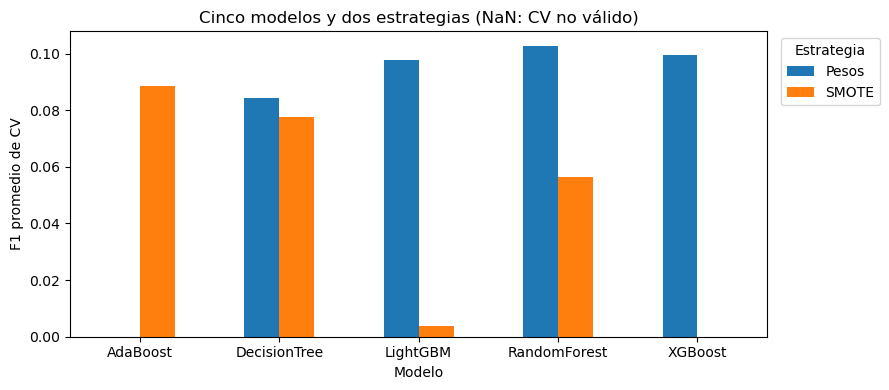

In [27]:
# Un solo gráfico de comparación por estrategia.
datos_grafico = tabla_seleccion.pivot(index="Modelo", columns="Estrategia", values="F1_CV")
ax = datos_grafico.plot.bar(figsize=(9, 4), rot=0)
ax.set_ylabel("F1 promedio de CV")
ax.set_title("Cinco modelos y dos estrategias (NaN: CV no válido)")
ax.legend(title="Estrategia", loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.savefig(RESULTADOS / "comparacion_cv.png", dpi=150)
plt.show()

In [28]:
# Revisar las mejores alternativas, sin consultar test.
revision_cv = tabla_seleccion.head(3).copy()
revision_cv["F1_ajuste_folds"] = [
    resultados_estrategia[fila.Estrategia][fila.Modelo]["F1_train_folds"]
    for fila in revision_cv.itertuples()
]
revision_cv["Brecha_ajuste_CV"] = revision_cv["F1_ajuste_folds"] - revision_cv["F1_CV"]
display(revision_cv)
display(Markdown(
    f"Se selecciona **{modelo_ganador_nombre} + {estrategia_ganadora}**, con F1 CV "
    f"**{resultado_ganador['F1_CV']:.5f}** y std **{resultado_ganador['F1_std']:.5f}**. "
    "La tabla permite revisar estabilidad y sobreajuste aparente; no prueba que el modelo "
    "esté libre de sobreajuste. Test permanece reservado para reportar resultados."
))

,Estrategia,Modelo,F1_CV,F1_fold_1,F1_fold_2,F1_fold_3,F1_std,Tiempo_busqueda,Observacion,F1_ajuste_folds,Brecha_ajuste_CV
0,Pesos,RandomForest,0.102741,0.098623,0.095345,0.114254,0.008250,15.487052,,0.240715,0.137975
1,Pesos,XGBoost,0.099444,0.092946,0.104456,0.100930,0.004815,1.794074,,0.147082,0.047638
2,Pesos,LightGBM,0.097681,0.090552,0.104160,0.098331,0.005574,2.626885,,0.170983,0.073302


Se selecciona **RandomForest + Pesos**, con F1 CV **0.10274** y std **0.00825**. La tabla permite revisar estabilidad y sobreajuste aparente; no prueba que el modelo esté libre de sobreajuste. Test permanece reservado para reportar resultados.

# 9. Tabla final obligatoria de las 10 combinaciones

La selección anterior ya está cerrada. Ahora se consulta test solo para reportar métricas de los diez pipelines finales. F1 Train se calcula con las observaciones originales, no con las filas sintéticas de SMOTE. Se usa predict normal; los umbrales de costos se tratarán después. Test no cambia el ganador ni se usa para elegir posteriormente los umbrales.

In [29]:
filas_finales = []
for estrategia, modelos in modelos_estrategia.items():
    for nombre, pipeline in modelos.items():
        r = resultados_estrategia[estrategia][nombre]
        if pipeline is None:
            filas_finales.append({
                "Estrategia": estrategia, "Modelo": nombre,
                **{col: np.nan for col in ["F1_Train", "F1_CV", "F1_Test", "Brecha_Train_Test",
                                          "Recall_Test", "Precision_Test", "AUC_ROC_Test"]},
                "Tiempo_busqueda": r["Tiempo_busqueda"], "Ganador_CV": False,
                "Observacion": r["Observacion"]
            })
            continue
        # La actualización puntual reutiliza métricas guardadas de modelos sin cambios.
        if "metricas_finales_guardadas" in globals():
            fila = metricas_finales_guardadas.loc[
                (metricas_finales_guardadas.Estrategia == estrategia) &
                (metricas_finales_guardadas.Modelo == nombre)
            ].iloc[0].to_dict()
            fila["Observacion"] = r.get("Observacion", "")
            filas_finales.append(fila)
            continue
        pred_train = pipeline.predict(X_train)
        pred_test = pipeline.predict(X_test)
        proba_test = pipeline.predict_proba(X_test)[:, list(pipeline.classes_).index(1)]
        metricas = evaluar_clasificacion(y_test, pred_test, proba_test)
        f1_train = f1_score(y_train, pred_train, pos_label=1, zero_division=0)
        r = resultados_estrategia[estrategia][nombre]
        filas_finales.append({
            "Estrategia": estrategia, "Modelo": nombre, "F1_Train": f1_train,
            "F1_CV": r["F1_CV"], "F1_Test": metricas["F1"],
            "Brecha_Train_Test": f1_train - metricas["F1"],
            "Recall_Test": metricas["Recall"], "Precision_Test": metricas["Precision"],
            "AUC_ROC_Test": metricas["AUC_ROC"], "Tiempo_busqueda": r["Tiempo_busqueda"],
            "Ganador_CV": nombre == modelo_ganador_nombre and estrategia == estrategia_ganadora,
            "Observacion": r.get("Observacion", "")
        })
tabla_10_combinaciones = pd.DataFrame(filas_finales).sort_values("F1_CV", ascending=False).reset_index(drop=True)
display(tabla_10_combinaciones)
tabla_10_combinaciones.to_csv(RESULTADOS / "tabla_10_combinaciones.csv", index=False)
fila_ganador_final = tabla_10_combinaciones.loc[tabla_10_combinaciones["Ganador_CV"]].iloc[0]
assert tabla_10_combinaciones["Ganador_CV"].sum() == 1
print("El ganador por CV se conserva:", modelo_ganador_nombre, estrategia_ganadora)

,Estrategia,Modelo,F1_Train,F1_CV,F1_Test,Brecha_Train_Test,Recall_Test,Precision_Test,AUC_ROC_Test,Tiempo_busqueda,Ganador_CV,Observacion
0,Pesos,RandomForest,0.099379,0.102741,0.098169,0.001210,0.542982,0.053962,0.627659,15.487052,True,
1,Pesos,XGBoost,0.100625,0.099444,0.098426,0.002199,0.560037,0.053954,0.634559,1.794074,False,
2,Pesos,LightGBM,0.102466,0.097681,0.098665,0.003801,0.565338,0.054049,0.635361,2.626885,False,
3,SMOTE,AdaBoost,0.079759,0.088507,0.080873,-0.001114,0.512330,0.043902,0.562897,55.560559,False,
4,Pesos,DecisionTree,0.086197,0.084355,0.088643,-0.002446,0.572482,0.048041,0.594648,1.888161,False,
5,SMOTE,DecisionTree,0.077132,0.077512,0.080622,-0.003489,0.583545,0.043302,0.547595,6.674210,False,
6,SMOTE,RandomForest,0.059546,0.056346,0.055082,0.004464,0.058078,0.052380,0.574221,39.938220,False,
7,SMOTE,LightGBM,0.000000,0.003643,0.000000,0.000000,0.000000,0.000000,0.617623,6.493841,False,
8,SMOTE,XGBoost,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.500000,4.992178,False,
9,Pesos,AdaBoost,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.122323,False,El weak learner obtuvo rendimiento peor que az...


El ganador por CV se conserva: RandomForest Pesos


# 10. Costos y probabilidades reales

Se crea un nuevo pipeline con el mismo tipo de modelo ganador y sus hiperparámetros, quitando SMOTE y todos los pesos de desbalance. No se vuelve a buscar hiperparámetros. Se conservan las proporciones reales de train; esto no garantiza calibración de probabilidades.

Los costos son **supuestos académicos**, no costos reales de Porto Seguro. FP: considerar riesgoso a quien no presenta siniestro, costo 100. FN: considerar de bajo riesgo a quien sí presenta siniestro, costo 1000. Se supone que FN cuesta diez veces FP y que los aciertos tienen costo cero.

In [30]:
C_FP, C_FN = 100, 1000
estimador_probabilidades = clone(modelo_ganador.named_steps["modelo"])
parametros_estimador = estimador_probabilidades.get_params(deep=True)
# Retirar pesos también del árbol base si el ganador fuera AdaBoost.
ajustes_sin_pesos = {p: None for p in parametros_estimador if p.endswith("class_weight")}
if "scale_pos_weight" in parametros_estimador:
    ajustes_sin_pesos["scale_pos_weight"] = None
if "is_unbalance" in parametros_estimador:
    ajustes_sin_pesos["is_unbalance"] = False
estimador_probabilidades.set_params(**ajustes_sin_pesos)
modelo_probabilidades = crear_pipeline(estimador_probabilidades, "Sin balanceo")
modelo_probabilidades.fit(X_train, y_train)
probabilidades_train = modelo_probabilidades.predict_proba(X_train)[:, list(modelo_probabilidades.classes_).index(1)]
with gzip.open(RESULTADOS / "modelo_probabilidades.pkl.gz", "wb", compresslevel=1) as archivo:
    cloudpickle.dump(modelo_probabilidades, archivo)
print("Modelo sin balanceo:", type(estimador_probabilidades).__name__)
print("Proporción positiva real:", y_train.eq(1).mean())

Modelo sin balanceo: RandomForestClassifier
Proporción positiva real: 0.036447143766183854


# 11. Umbral teórico y empírico

Con costo cero para aciertos y probabilidades que reflejen el riesgo real, el umbral teórico es `C_FP / (C_FP + C_FN)`. El manual minimiza el costo sobre las filas originales de train mediante una grilla de 0,01 a 0,50. Este mínimo es dentro de muestra y puede ser optimista. Test no interviene.

In [31]:
p_teorico = C_FP / (C_FP + C_FN)
grilla_umbrales = np.arange(1, 51) / 100
filas_costos = []
for umbral in grilla_umbrales:
    pred = (probabilidades_train >= umbral).astype(int)
    matriz = confusion_matrix(y_train, pred, labels=[0, 1])
    filas_costos.append({"Umbral": float(umbral), "FP": int(matriz[0, 1]),
                        "FN": int(matriz[1, 0]),
                        "Costo_train": calcular_costo(y_train, pred, C_FP, C_FN)})
tabla_costos_train = pd.DataFrame(filas_costos)
umbral_empirico_manual = float(tabla_costos_train.loc[tabla_costos_train["Costo_train"].idxmin(), "Umbral"])
display(tabla_costos_train)
print("Teórico:", p_teorico, "| Manual:", umbral_empirico_manual)
print("Costo mínimo en train:", tabla_costos_train["Costo_train"].min())
tabla_costos_train.to_csv(RESULTADOS / "costos_umbrales_train.csv", index=False)

,Umbral,FP,FN,Costo_train
0,0.01,458814,0,45881400
1,0.02,453038,50,45353800
2,0.03,295108,3559,33069800
3,0.04,121196,9600,21719600
4,0.05,57150,12641,18356000
5,0.06,28037,14382,17185700
6,0.07,11904,15690,16880400
7,0.08,5654,16326,16891400
8,0.09,2712,16707,16978200
9,0.10,1376,16939,17076600


Teórico: 0.09090909090909091 | Manual: 0.07
Costo mínimo en train: 16880400


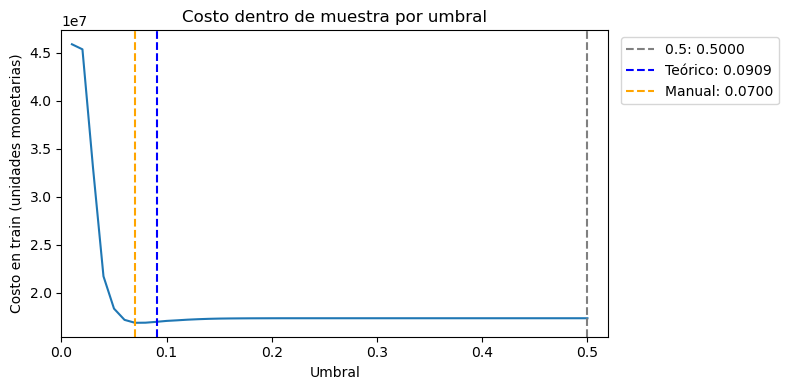

In [32]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(tabla_costos_train["Umbral"], tabla_costos_train["Costo_train"])
for nombre, umbral, color in [("0.5", 0.5, "gray"), ("Teórico", p_teorico, "blue"),
                              ("Manual", umbral_empirico_manual, "orange")]:
    ax.axvline(umbral, linestyle="--", color=color, label=f"{nombre}: {umbral:.4f}")
ax.set_xlabel("Umbral")
ax.set_ylabel("Costo en train (unidades monetarias)")
ax.set_title("Costo dentro de muestra por umbral")
ax.set_xlim(0, 0.52)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.savefig(RESULTADOS / "costo_umbral_train.png", dpi=150)
plt.show()

# 12. TunedThresholdClassifierCV

Se minimiza el mismo costo con signo negativo mediante tres folds estratificados de train y la misma grilla. La CV ajusta copias del modelo con hiperparámetros fijos; no es una nueva búsqueda de modelos. Se reajusta su copia final con todo train. No se usa cv=prefit sobre los mismos datos de ajuste ni se consulta test para elegir umbral.

In [33]:
try:
    from sklearn.model_selection import TunedThresholdClassifierCV
except ImportError as error:
    raise ImportError('Se requiere scikit-learn >= 1.5. Instala: python -m pip install "scikit-learn>=1.5"') from error

scorer_costo = make_scorer(calcular_costo, greater_is_better=False,
                          C_FP=C_FP, C_FN=C_FN, pos_label=1)
ajustador_umbral = TunedThresholdClassifierCV(
    clone(modelo_probabilidades), scoring=scorer_costo, response_method="predict_proba",
    thresholds=grilla_umbrales,
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=SEMILLA),
    refit=True, n_jobs=1, random_state=SEMILLA, store_cv_results=True
)
ajustador_umbral.fit(X_train, y_train)
umbral_tuned = float(ajustador_umbral.best_threshold_)
tabla_umbrales = pd.DataFrame({
    "Metodo": ["0.5", "Teórico", "Manual (train)", "Tuned (CV de train)"],
    "Umbral": [0.5, p_teorico, umbral_empirico_manual, umbral_tuned]
})
display(tabla_umbrales)
tabla_umbrales.to_csv(RESULTADOS / "umbrales.csv", index=False)
with gzip.open(RESULTADOS / "ajustador_umbral.pkl.gz", "wb", compresslevel=1) as archivo:
    cloudpickle.dump(ajustador_umbral, archivo)

,Metodo,Umbral
0,0.5,0.500000
1,Teórico,0.090909
2,Manual (train),0.070000
3,Tuned (CV de train),0.080000


# 13. Evaluación final en Test

Se aplican las políticas predefinidas al modelo de probabilidades sin balanceo. El ganador seleccionado por CV también se reporta con su predict normal. Se conservan todos los umbrales fijados en train: ningún resultado de test modifica modelo o umbral. El ahorro se calcula contra la política de umbral 0,5, con los mismos costos académicos.

In [34]:
probabilidades_test = modelo_probabilidades.predict_proba(X_test)[:, list(modelo_probabilidades.classes_).index(1)]
politicas = {
    "Todo 0": np.zeros(len(y_test), dtype=int),
    "Umbral 0.5": (probabilidades_test >= 0.5).astype(int),
    "Teórico": (probabilidades_test >= p_teorico).astype(int),
    "Manual": (probabilidades_test >= umbral_empirico_manual).astype(int),
    "Tuned": (probabilidades_test >= umbral_tuned).astype(int),
    f"Ganador CV: {modelo_ganador_nombre} + {estrategia_ganadora}": modelo_ganador.predict(X_test)
}
filas_politicas = []
for politica, pred in politicas.items():
    m = evaluar_clasificacion(y_test, pred, C_FP=C_FP, C_FN=C_FN)
    filas_politicas.append({"Politica": politica, **m})
comparacion_test = pd.DataFrame(filas_politicas).drop(columns="AUC_ROC")
costo_0_5 = int(comparacion_test.loc[comparacion_test["Politica"] == "Umbral 0.5", "Costo_total"].iloc[0])
comparacion_test["Ahorro_vs_0.5"] = costo_0_5 - comparacion_test["Costo_total"]
comparacion_test = comparacion_test.sort_values("Costo_total", kind="stable").reset_index(drop=True)
display(comparacion_test)
comparacion_test.to_csv(RESULTADOS / "comparacion_test.csv", index=False)

,Politica,TN,FP,FN,TP,Precision,Recall,F1,Costo_total,Ahorro_vs_0.5
0,Tuned,113202,1502,4152,187,0.110716,0.043097,0.062044,4302200,36800
1,Teórico,113988,716,4248,91,0.112763,0.020973,0.035367,4319600,19400
2,Manual,111676,3028,4023,316,0.094498,0.072828,0.082260,4325800,13200
3,Todo 0,114704,0,4339,0,0.000000,0.000000,0.000000,4339000,0
4,Umbral 0.5,114704,0,4339,0,0.000000,0.000000,0.000000,4339000,0
5,Ganador CV: RandomForest + Pesos,73400,41304,1983,2356,0.053962,0.542982,0.098169,6113400,-1774400


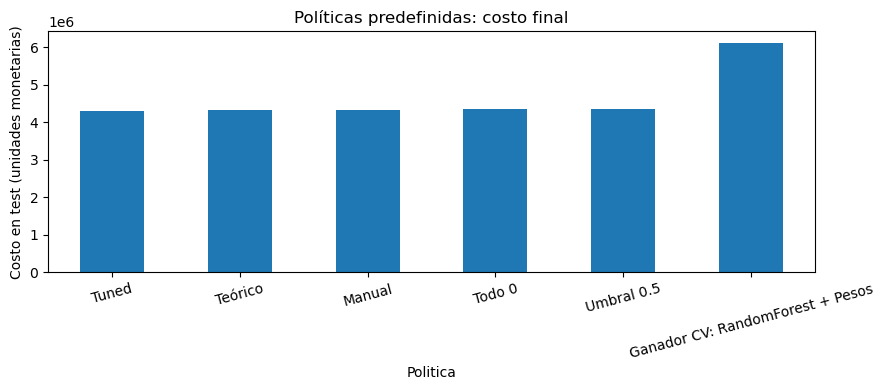

Umbral 0.5


,Predicho 0,Predicho 1
Real 0,114704,0
Real 1,4339,0


Teórico


,Predicho 0,Predicho 1
Real 0,113988,716
Real 1,4248,91


Tuned


,Predicho 0,Predicho 1
Real 0,113202,1502
Real 1,4152,187


In [35]:
ax = comparacion_test.plot.bar(x="Politica", y="Costo_total", figsize=(9, 4), legend=False, rot=15)
ax.set_ylabel("Costo en test (unidades monetarias)")
ax.set_title("Políticas predefinidas: costo final")
plt.tight_layout()
plt.savefig(RESULTADOS / "costos_politicas_test.png", dpi=150)
plt.show()
# Matrices como tablas para no agregar gráficos innecesarios.
for politica in ["Umbral 0.5", "Teórico", "Tuned"]:
    print(politica)
    display(pd.DataFrame(confusion_matrix(y_test, politicas[politica], labels=[0, 1]),
                         index=["Real 0", "Real 1"], columns=["Predicho 0", "Predicho 1"]))

In [36]:
menor_costo = comparacion_test.iloc[0]
display(Markdown(
    f"El menor costo observado corresponde a **{menor_costo['Politica']}**: "
    f"**{int(menor_costo['Costo_total']):,}**, con ahorro **{int(menor_costo['Ahorro_vs_0.5']):,}** "
    "frente a 0,5. Bajar el umbral permite más positivos, pero también puede aumentar FP. "
    "El mínimo manual de train es optimista; la evaluación de test no se usa para recalcularlo "
    "ni para cambiar el ganador por CV. Los valores son académicos y no implican causalidad."
))

El menor costo observado corresponde a **Tuned**: **4,302,200**, con ahorro **36,800** frente a 0,5. Bajar el umbral permite más positivos, pero también puede aumentar FP. El mínimo manual de train es optimista; la evaluación de test no se usa para recalcularlo ni para cambiar el ganador por CV. Los valores son académicos y no implican causalidad.

# 14. Análisis de sensibilidad

Exactamente cuatro escenarios, con FP=100 y FN=200, 500, 1000 y 2000. Los conteos de la grilla de train se reutilizan porque no dependen de los costos. Cada umbral se elige solo con train y luego se aplica una vez a las probabilidades de test. No se selecciona un escenario con test.

In [37]:
filas_sensibilidad = []
for costo_fn in [200, 500, 1000, 2000]:
    costos_escenario = tabla_costos_train["FP"] * 100 + tabla_costos_train["FN"] * costo_fn
    umbral_escenario = float(tabla_costos_train.loc[costos_escenario.idxmin(), "Umbral"])
    pred = (probabilidades_test >= umbral_escenario).astype(int)
    m = evaluar_clasificacion(y_test, pred, C_FP=100, C_FN=costo_fn)
    filas_sensibilidad.append({
        "Escenario": len(filas_sensibilidad) + 1, "C_FP": 100, "C_FN": costo_fn,
        "Ratio_FN_FP": costo_fn / 100, "Umbral_teorico": 100 / (100 + costo_fn),
        "Umbral_empirico_train": umbral_escenario, "FP_test": m["FP"], "FN_test": m["FN"],
        "Precision_test": m["Precision"], "Recall_test": m["Recall"],
        "F1_test": m["F1"], "Costo_test": m["Costo_total"]
    })
sensibilidad_costos = pd.DataFrame(filas_sensibilidad)
display(sensibilidad_costos)
sensibilidad_costos.to_csv(RESULTADOS / "sensibilidad_costos.csv", index=False)

,Escenario,C_FP,C_FN,Ratio_FN_FP,Umbral_teorico,Umbral_empirico_train,FP_test,FN_test,Precision_test,Recall_test,F1_test,Costo_test
0,1,100,200,2.0,0.333333,0.13,51,4327,0.190476,0.002766,0.005452,870500
1,2,100,500,5.0,0.166667,0.11,215,4303,0.143426,0.008297,0.015686,2173000
2,3,100,1000,10.0,0.090909,0.07,3028,4023,0.094498,0.072828,0.082260,4325800
3,4,100,2000,20.0,0.047619,0.05,14231,3245,0.071387,0.252132,0.111269,7913100


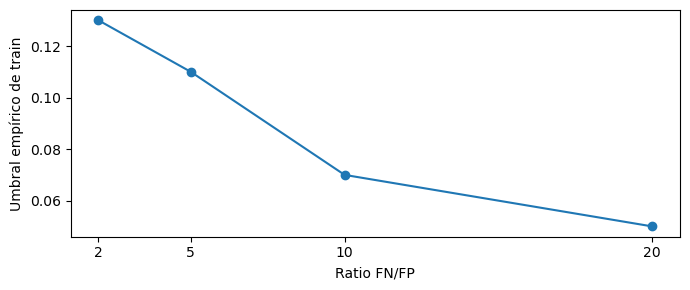

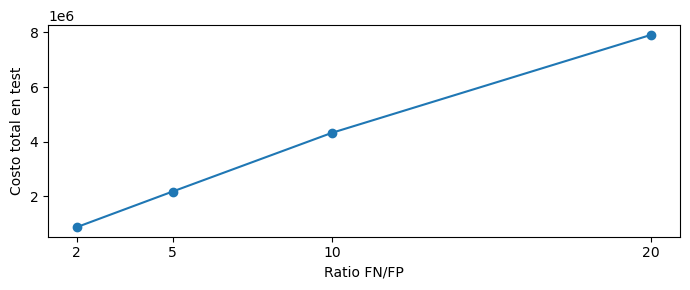

In [38]:
# Solo dos gráficos simples.
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(sensibilidad_costos["Ratio_FN_FP"], sensibilidad_costos["Umbral_empirico_train"], marker="o")
ax.set_xlabel("Ratio FN/FP")
ax.set_ylabel("Umbral empírico de train")
ax.set_xticks(sensibilidad_costos["Ratio_FN_FP"])
plt.tight_layout()
plt.savefig(RESULTADOS / "sensibilidad_umbral.png", dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(sensibilidad_costos["Ratio_FN_FP"], sensibilidad_costos["Costo_test"], marker="o")
ax.set_xlabel("Ratio FN/FP")
ax.set_ylabel("Costo total en test")
ax.set_xticks(sensibilidad_costos["Ratio_FN_FP"])
plt.tight_layout()
plt.savefig(RESULTADOS / "sensibilidad_costo.png", dpi=150)
plt.show()

Cuando FN cuesta relativamente más, el umbral tiende a bajar y el recall aumenta, generalmente a costa de más FP. Todos los umbrales de los escenarios se eligieron con train, nunca test. Los costos totales de escenarios distintos también cambian por el valor monetario de FN, no solo por la clasificación.

# 15. Preparación para el dashboard

Se exportan únicamente etiquetas y probabilidades del modelo sin balanceo original. Permiten recalcular decisiones, matriz de confusión, métricas y costos para cualquier umbral sin entrenar. La configuración contiene los costos y umbrales calculados. No se construye Streamlit.

In [39]:
carpeta_dashboard = RAIZ / "dashboard"
carpeta_dashboard.mkdir(exist_ok=True)
datos_dashboard = pd.DataFrame({"y_real": y_test.to_numpy(),
                                "probabilidad_clase_1": probabilidades_test})
datos_dashboard.to_csv(carpeta_dashboard / "datos_dashboard.csv", index=False)
config_dashboard = {"C_FP": C_FP, "C_FN": C_FN,
                    "umbral_teorico": p_teorico,
                    "umbral_empirico_manual": umbral_empirico_manual,
                    "umbral_tuned": umbral_tuned}
with open(carpeta_dashboard / "config.json", "w") as archivo:
    json.dump(config_dashboard, archivo, indent=2)
print("Filas exportadas:", len(datos_dashboard))
display(datos_dashboard.head())

Filas exportadas: 119043


,y_real,probabilidad_clase_1
0,0,0.063153
1,0,0.025894
2,0,0.034689
3,0,0.029897
4,0,0.024934


# 16. Resumen final

Los siguientes valores se generan a partir de esta ejecución; no se fijan ganadores ni métricas de antemano.

In [40]:
estrategia_general = tabla_seleccion.groupby("Estrategia")["F1_CV"].mean().idxmax()
resumen_final = {
    "dataset": "Porto Seguro", "registros": len(df),
    "porcentaje_positivo": float(y.eq(1).mean() * 100),
    "combinaciones": len(tabla_10_combinaciones), "estrategia_general_por_media_CV": estrategia_general,
    "ganador": modelo_ganador_nombre, "estrategia_ganadora": estrategia_ganadora,
    "F1_CV": float(resultado_ganador["F1_CV"]), "F1_Test": float(fila_ganador_final["F1_Test"]),
    "C_FP": C_FP, "C_FN": C_FN, "umbral_teorico": p_teorico,
    "umbral_empirico_manual": umbral_empirico_manual, "umbral_tuned": umbral_tuned,
    "politica_menor_costo_test": menor_costo["Politica"],
    "costo_menor_politica_test": int(menor_costo["Costo_total"])
}
with open(RESULTADOS / "resumen_final.json", "w") as archivo:
    json.dump(resumen_final, archivo, ensure_ascii=False, indent=2)
texto_resumen = f"""**Porto Seguro:** {len(df):,} registros, clase positiva {y.eq(1).mean()*100:.2f}%.

**5 modelos × 2 estrategias.** Mejor estrategia por F1 CV medio: {estrategia_general}.
Ganador: **{modelo_ganador_nombre} + {estrategia_ganadora}**;
F1 CV **{resultado_ganador['F1_CV']:.5f}**, F1 Test **{fila_ganador_final['F1_Test']:.5f}**.

**Costos académicos:** FP={C_FP}, FN={C_FN}.
Umbral teórico **{p_teorico:.4f}**, manual **{umbral_empirico_manual:.2f}**, tuned **{umbral_tuned:.2f}**.
Menor costo final observado: **{menor_costo['Politica']}**, **{int(menor_costo['Costo_total']):,}**.

Mejor F1 no garantiza menor costo. Los costos son supuestos, las asociaciones no demuestran
causalidad y test no cambió la selección por CV ni los umbrales elegidos con train.
Los datos del futuro dashboard quedaron exportados sin construir una aplicación."""
display(Markdown(texto_resumen))
(RESULTADOS / "resumen_final.md").write_text(texto_resumen, encoding="utf-8")

**Porto Seguro:** 595,212 registros, clase positiva 3.64%.

**5 modelos × 2 estrategias.** Mejor estrategia por F1 CV medio: Pesos.
Ganador: **RandomForest + Pesos**;
F1 CV **0.10274**, F1 Test **0.09817**.

**Costos académicos:** FP=100, FN=1000.
Umbral teórico **0.0909**, manual **0.07**, tuned **0.08**.
Menor costo final observado: **Tuned**, **4,302,200**.

Mejor F1 no garantiza menor costo. Los costos son supuestos, las asociaciones no demuestran
causalidad y test no cambió la selección por CV ni los umbrales elegidos con train.
Los datos del futuro dashboard quedaron exportados sin construir una aplicación.

620

**Cierre:** las métricas y costos corresponden a los modelos y supuestos de esta ejecución. No se afirma causalidad ni se presentan los costos como cifras reales de Porto Seguro.